# Assignment 2, Question 1 — Companion Notebook

How does an architecture carry observations to a forecast? Before you design a river forecasting system in Question 1, spend about **20 minutes** here watching small forecasters succeed and fail. The notebook looks at missing information, operation order, joint space–time processing, spatial reach, and attention and its cost.

Every model is **already trained**. You do not train anything and you do not need a GPU. Run the cells in order, read the plots, use the controls, and think about the design decision behind each result: what information can reach a forecast, which blocks create that path, and what each path costs. These are the questions you will face again in the river design. Seeing them on toy problems first should make that design easier to reason about and to defend.

This notebook is **optional and ungraded**, and you do not submit anything from it. The *Think about* prompts are for your own reflection. Some of what you find here may be directly useful for the design question, and some may not.

The notebook uses two synthetic settings with sixteen sensors arranged in a line: a moving field, and a signal broadcast from a marked source. In each setting, models use past sensor readings to predict the value at each sensor at the next time step.

An **episode** is one independently generated example: eight consecutive time steps of measurements from all sixteen sensors, together with the target values for the next step. Models receive the observed window; the next-step targets are withheld and used to measure forecast error. Each setting specifies how the readings and targets are generated.

Every forecast head reads only its own sensor's latest hidden representation. **MAE** denotes mean absolute error; lower is better.

**Protocol.** Models are pretrained with a common training budget and validation-based checkpoint selection, then evaluated on shared held-out episodes. Figures report mean ± SD across three independent training runs; SD describes run variation, not a confidence interval. Single-episode illustrations are identified separately; configuration details are in the checkpoint manifest.

In [4]:
import torch
from assignment2 import visuals, widgets
from assignment2.worlds import moving_pair

torch.set_num_threads(2)
%matplotlib inline

## 1. Information outside a sensor's history

> **Building blocks — S and T**
>
> **T (temporal)** combines the current and two preceding times at the same sensor through a causal temporal convolution.
>
> **S (spatial)** combines a sensor and its two immediate neighbors at the same time through a spatial convolution.
>
> Both apply learned nonlinear transformations and retain residual connections that carry their inputs forward.

The field moves one sensor to the right each step, so sensor 8’s next value equals sensor 7’s latest reading. These two valid examples have identical histories at sensor 8 but different latest readings at sensor 7.

The temporal-only model stacks four T blocks. Its forecast cannot access sensor 7’s reading; adding more T blocks still mixes only sensor 8’s own history.


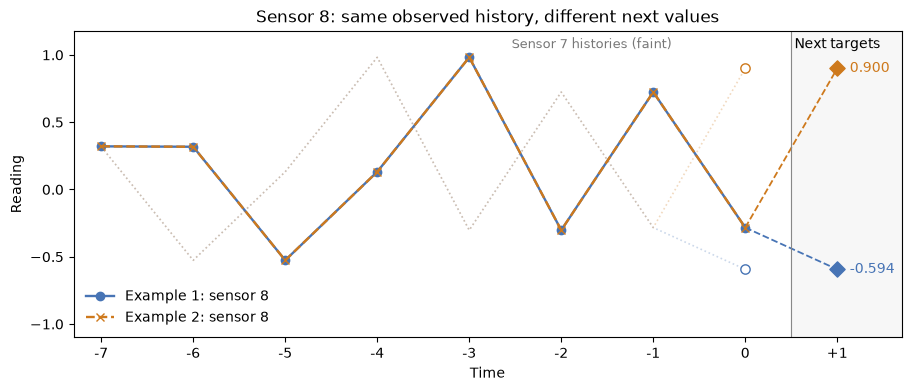

In [5]:
first, second = moving_pair()
visuals.show(visuals.identical_histories(first, second))

> **Forecast losses — MAE and MSE**
>
> Suppose one prediction $p$ must serve $n$ equally weighted targets $y_1,\ldots,y_n$. Mean absolute error (MAE) and mean squared error (MSE) are:
>
> $$
> L_{\mathrm{MAE}}(p)=\frac{1}{n}\sum_{i=1}^{n}|p-y_i|,
> \qquad
> L_{\mathrm{MSE}}(p)=\frac{1}{n}\sum_{i=1}^{n}(p-y_i)^2.
> $$
>
> A training objective specifies which errors the forecaster is trained to minimize. The bundled models train and evaluate with MAE; this prompt compares the two objectives.

**Think about 1 — Missing information and the training objective.**

**(a) Identical inputs.** Explain why a deterministic forecaster using only sensor 8's history must make the same prediction $p$ for both examples.

**(b) Two possible targets.** Treat the displayed targets, −0.594 and 0.900, as exact here and weight them equally. Write MAE and MSE as functions of $p$. For each loss, find its minimum value and **all** predictions that attain it.

**(c) General case.** For any $n\geq1$ equally weighted targets sharing one prediction, independently prove from the formulas that MSE is minimized by the arithmetic mean and MAE by a median. Characterize all minimizing predictions, accounting for odd and even sample sizes and repeated target values.


## 2. Learning space–time representations

Continue with the two moving-field examples from Part 1. Sensor 8's next value comes from sensor 7's latest reading. A T-only stack cannot access that neighbor; adding S blocks creates the missing spatial path.

At each observed sensor–time position, the model stores a **representation**: a learned vector of features. Blocks update these vectors by combining information from other positions.

> **Combining blocks — alternating S and T**
>
> An **S-first** stack repeats S → T; a **T-first** stack repeats T → S. S combines neighboring representations at the same time; T combines representations at the same sensor over the current and two preceding times. Repeating pairs extends reach in both dimensions.

The plot compares four T blocks with three S → T pairs on the same two examples. Each panel shows sensor 8's history and the forecasts at +1. Forecast points and vertical error bars show mean ± SD across three training runs; black diamonds mark the true targets, which the models do not receive.


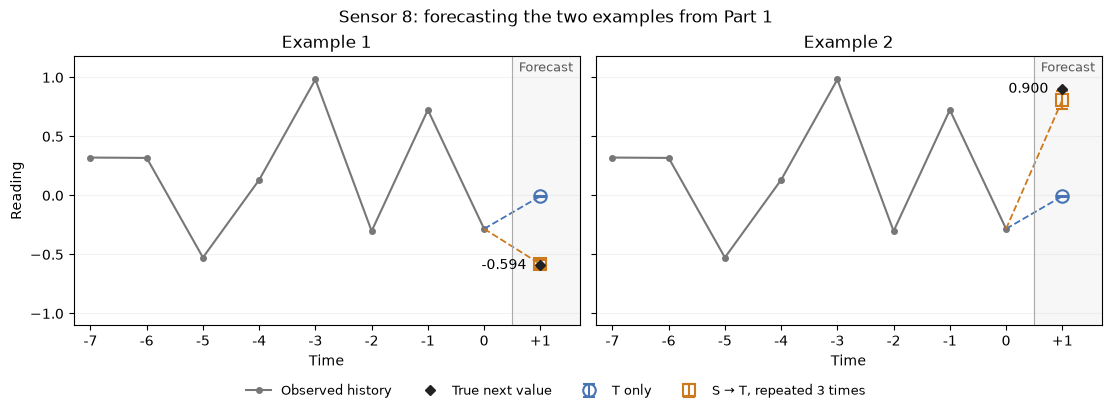

In [6]:
visuals.show(visuals.moving_pair_predictions(first, second))


T alone makes the same forecast for both examples. Alternating S and T makes different forecasts close to their respective targets because it can use upstream information. These two predictions illustrate access to information, rather than average accuracy across a dataset.


Instead of processing the two dimensions successively, we can combine them in one operation.

> **Building block — ST**
>
> **ST (joint space–time convolution)** updates each representation using a causal 3 × 3 patch: the current and two preceding times across the sensor and its two immediate neighbors.
>
> Its kernel learns a separate weight matrix for each combination of temporal lag and sensor offset. For example, “left neighbor now” and “same sensor one step earlier” can contribute differently. A 3 × 3 kernel does not require space and time to have identical relationships: time remains causal, while space includes neighbors on both sides.

One ST block and one alternating pair have the same structural reach. Their transformations differ: an alternating pair passes through an intermediate learned representation and a nonlinearity between operations.

> **Architectural assumptions — how information is combined**
>
> **Alternating S/T** organizes learning into separate spatial and temporal stages, combining their results through feature vectors. This favors composing the two kinds of transformation; it does not require the physical process itself to separate into independent spatial and temporal effects.
>
> **Joint ST** learns interactions across a space–time patch directly, without imposing that sequence of separate stages.
>
> **Both** use local neighborhoods and reuse kernel weights across positions and times, favoring reusable local patterns. Position coordinates can still allow location-dependent behavior.

The moving world has the same local transport rule along the sensor line, making this reuse a useful bias. In a river, adjacent sensor indices may represent very different physical distances or connections. The model's definition of a neighbor then needs more care. Neither approach is automatically better; the structure should suit the dependencies of the task.


**Think about 2 — What must the intermediate representation preserve?**

A signal passes between neighboring sensors. Forecasting its movement requires recognizing which sensor observed it first.

For S → T and T → S, explain what information the first block must preserve so the second can recognize this relationship. Describe a possible intermediate representation that would make the relationship impossible to recover.


**Think about 3 — How much depth is needed?** Suppose a forecast requires an observation four sensors to the left and six time steps before the latest observed time, $t=0$. Find the minimum number of alternating S–T pairs and the minimum number of ST blocks needed. Justify both using spatial and temporal reach.


## 3. Joint space–time attention

Convolutions build representations through local patches. Attention can combine information from distant positions directly.

> **Building block — A**
>
> **A (joint space–time attention)** learns input-dependent weights for combining all observed tokens. Every token has a direct path to every other. All these tokens are available before forecast issuance; future measurements are excluded.
>
> Each **token** is the learned representation at one observed sensor–time position. With $H$ observed times and $N$ sensors, there are $L=HN$ tokens.

We compare three A blocks with three ST blocks, both at width 32. The ST stack reaches at most three sensors away; attention has a direct path regardless of distance. Having a path still leaves the model to learn how to use it.


Testing that claim requires a forecast that depends on a single distant sensor whose distance we can control, while everything else stays fixed. The **relay world** is built for this. A marked source broadcasts its latest reading to every other sensor at the next step, as a central controller's command might reach every location at once. Every reading is drawn independently and uniformly between −1 and 1, so a sensor's own history says nothing about its next value; only the source does. Moving the forecast sensor away from the source places the needed information inside or outside the ST stack's three-sensor reach. Models receive the readings, source marker, and time/sensor coordinates.


Held-out errors at near (1–3) and far (4–15) distances, mean ± SD across three runs:


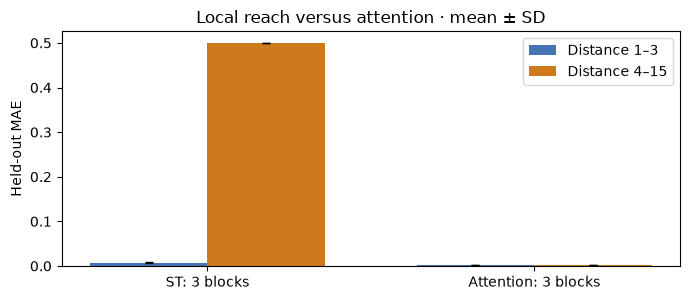

In [7]:
visuals.show(visuals.relay_scores())

Three ST blocks forecast accurately near the source but not at a distance; attention is accurate at every distance tested. These held-out results do not imply that attention is best for every forecasting task.


To see the failure in single forecasts, take two examples that differ only in the source's latest reading. The forecast sensor's history stays fixed. The plot identifies the source, forecast sensor, and their distance; points and error bars show forecast mean ± SD across three runs. Use the distance control to compare locations inside and outside the ST stack's reach.


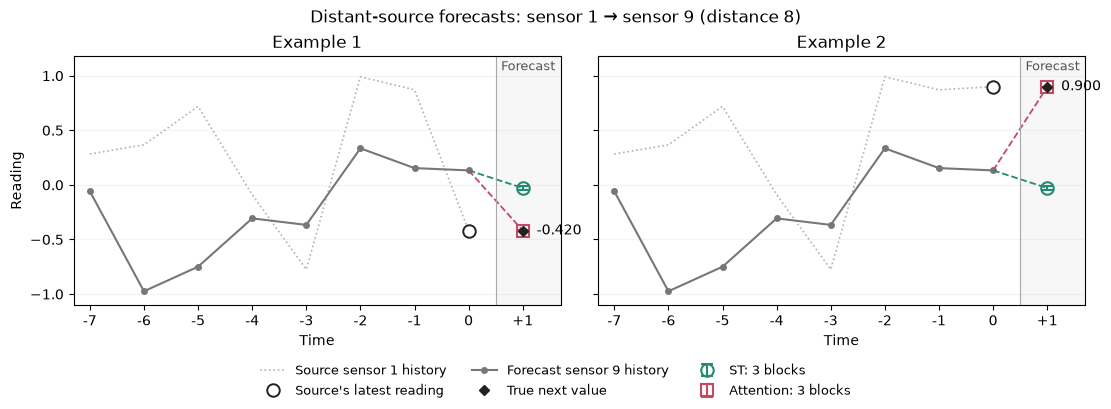

In [8]:
widgets.distant_pair();

The reach map marks every observed input that can influence one forecast, for a chosen stack and depth.

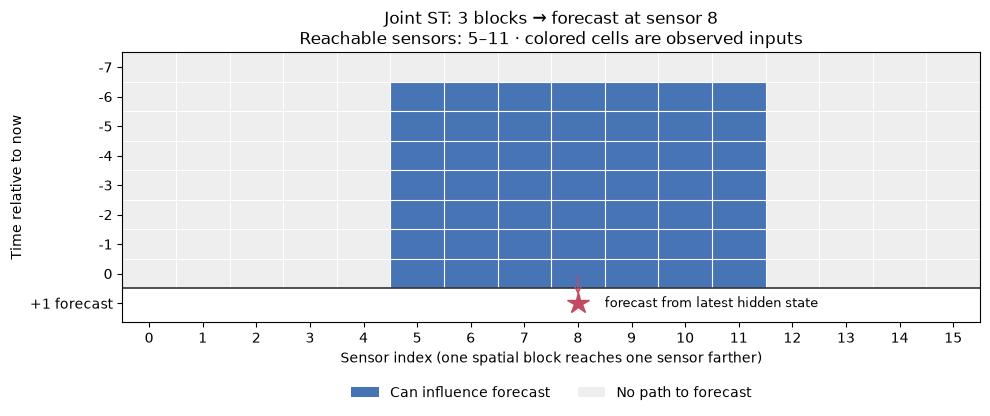

In [9]:
widgets.receptive_fields();

Where does the forecast sensor's latest token look? The grid shows, for one training run, each head's average weight on the source's latest token across held-out episodes; the maps show one episode's readings and the selected head's weights over all tokens. In every run at least one head places nearly all its weight on the source while the rest stay near the uniform value 1/128, but which block and head takes this role differs between runs, and in one run it is already the first block.


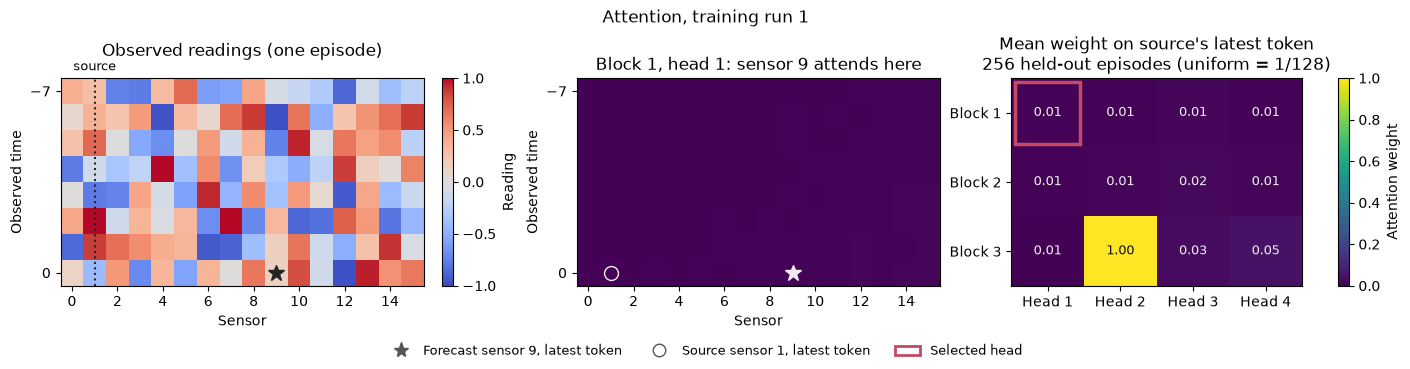

In [10]:
widgets.attention_lab();

> **Computational cost — mixing tokens**
>
> For $L=HN$ tokens and hidden width $d$, the leading mixing costs per block are:
>
> $$
> C_A=2L^2d,\qquad C_{ST}=9Ld^2.
> $$
>
> These count query–key products and weighted values for attention, and a dense 3 × 3 ST convolution including padded taps. They exclude other model operations and are not measured runtimes. Attention's direct connections come with a cost that grows quadratically in token count.


**Think about 4 — Debug the ST forecaster.** Treat the ST results as a model you have been asked to fix.

- **Diagnose.** Which quick checks, without retraining, would establish why it fails at a distance? What result do you expect from each?
- **Fix.** Propose two different fixes. For each, use reach to determine how large it must be to cover every distance, and compare their mixing costs.
- **Verify.** Before retraining, predict what the fixed model's error across distances and its paired forecasts should show. What result would mean the path now exists but the model is not using it?
